# Sampling from a GP posterior

Sampling lets us explore functions compatible with our measurements. We'll
start by sampling function values at a fixed set of locations, then draw a
function that we can evaluate at new locations and differentiate.

We use the three observations from [First posterior](first-posterior.ipynb),
with measurement-error variance `0.02`.

In [1]:
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

from gpex import (
    FeaturePosteriorPath,
    FunctionalBlock,
    FunctionalDataset,
    FunctionalQuery,
    GaussianProcess,
    ObservationBlock,
    kernels,
    operators,
)

x_observed = jnp.array([[-1.4], [-1.0], [1.2]])
y_observed = jnp.array([-0.8, -0.5, 0.7])

dataset = FunctionalDataset([
    ObservationBlock.from_arrays(
        x_observed, y_observed,
        variance=0.02, name="observed_values", max_size=3,
    )
])
gp = GaussianProcess(
    kernels.RBFKernel(variance=1.0, lengthscale=0.5)
)
posterior = gp.condition(dataset)

## Sample values at fixed locations

The posterior function values at any fixed set of locations are jointly
Gaussian. We can therefore sample them together from a multivariate Gaussian
distribution, preserving their correlations.

Let's choose nine locations and draw five samples with `posterior.sample`.
The identity operator asks for function values at those locations.

In [2]:
x_sample = jnp.linspace(-2.0, 2.0, 9)[:, None]
query = FunctionalQuery([
    FunctionalBlock(x_sample, operators.Identity(), name="function")
])
samples = posterior.sample(
    jax.random.key(2), query, sample_count=5
)["function"]

`samples` has shape `(5, 9)`. Each row is one joint draw, containing a value at
each of the nine locations. In the plot, each color shows one row.

For context, we'll show the posterior mean and pointwise 95% intervals in the
background. `predict_marginals` computes the means and variances needed for
this band.

In [3]:
x_plot = jnp.linspace(-2.0, 2.0, 101)[:, None]
function_query = FunctionalQuery([
    FunctionalBlock(x_plot, operators.Identity(), name="function")
])
function_posterior = posterior.predict_marginals(function_query)

In [4]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.8),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})


def plot_posterior(ax, x, prediction, name):
    mean = prediction.mean[name]
    sd = jnp.sqrt(jnp.maximum(prediction.variance[name], 0.0))
    ax.fill_between(
        x, mean - 1.96 * sd, mean + 1.96 * sd,
        color="#1F4E79", alpha=0.12, linewidth=0,
        label="95% posterior interval", zorder=0,
    )
    ax.plot(
        x, mean, color="#1F4E79", linestyle="--", linewidth=1.2,
        alpha=0.7, label="Posterior mean", zorder=1,
    )


def plot_draws(ax, x, other_draws, highlighted):
    for i, values in enumerate(other_draws):
        ax.plot(
            x, values, color="#6D597A", linewidth=0.9, alpha=0.3,
            label="Other draws" if i == 0 else None,
        )
    ax.plot(
        x, highlighted, color="#6D597A", linewidth=1.8,
        label="Highlighted draw", zorder=3,
    )

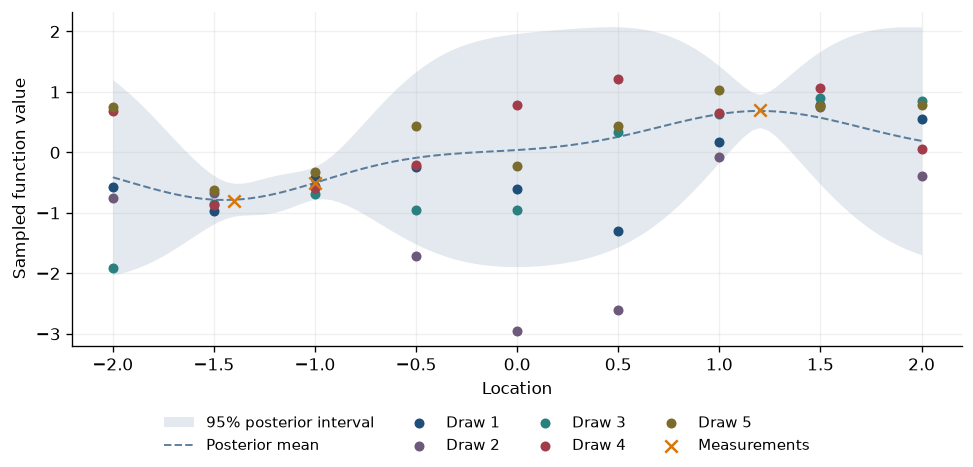

In [5]:
fig, ax = plt.subplots(layout="constrained")
plot_posterior(ax, x_plot[:, 0], function_posterior, "function")
colors = ["#1F4E79", "#6D597A", "#2A7F7F", "#A23B4A", "#7B6B2D"]
for i, values in enumerate(samples):
    ax.scatter(
        x_sample[:, 0], values,
        color=colors[i], s=25, label=f"Draw {i + 1}", zorder=3,
    )
ax.scatter(
    x_observed[:, 0], y_observed,
    color="#D97706", marker="x", s=55, label="Measurements", zorder=4,
)
ax.set(xlabel="Location", ylabel="Sampled function value")
fig.legend(loc="outside lower center", ncol=4, frameon=False, fontsize=9)
plt.show()

The uncertainty grows in the large gap between the observations. The samples
reflect this by spreading out more there.

This gives us values at the chosen locations. If we want a sample on a finer
fixed grid, we can include that whole grid in the query and sample its values
jointly.

## Sample a function

A GP is also a distribution over functions. We can draw a function and then
evaluate it wherever we need, including locations chosen after the draw.

`FeaturePosteriorPath` gives us an approximate function draw. Larger
`feature_count` values improve the approximation on average, but make the
function slower to evaluate.

In [6]:
f_sample = FeaturePosteriorPath(
    posterior, jax.random.key(7), feature_count=1024
)

`f_sample` takes one location and returns one value. For example, in this
one-dimensional problem we can evaluate it at `0.25` by passing an array with
one entry.

In [7]:
print(f"f(0.25) = {f_sample(jnp.array([0.25])):.3f}")

f(0.25) = 0.467


To plot this function, use `jax.vmap` to evaluate it across the plotting grid.
We can also evaluate the same draw at new locations between the grid points.

In [8]:
function_values = jax.vmap(f_sample)(x_plot)

new_locations = jnp.array([[-0.75], [0.25], [1.75]])
new_values = jax.vmap(f_sample)(new_locations)

## Differentiate the sampled function

We can apply operators to the sampled function. Here the RBF kernel gives
smooth functions, so we can use `jax.grad` to differentiate it. Our input has
one coordinate, so each gradient has one component: the derivative with respect
to location.


In [9]:
df_sample = jax.grad(f_sample)
derivative_values = jax.vmap(df_sample)(x_plot)[:, 0]

Let's add eleven more function draws to see how their values and derivatives
vary. For the derivative plot's background, `PartialDerivative` asks the GP
for the derivative mean and variance directly.

In [10]:
derivative_query = FunctionalQuery([
    FunctionalBlock(
        x_plot, operators.PartialDerivative(axis=0), name="derivative"
    )
])
derivative_posterior = posterior.predict_marginals(derivative_query)

In [11]:
other_values = []
other_derivatives = []
for key in jax.random.split(jax.random.key(8), 11):
    draw = FeaturePosteriorPath(posterior, key, feature_count=1024)
    other_values.append(jax.vmap(draw)(x_plot))
    other_derivatives.append(jax.vmap(jax.grad(draw))(x_plot)[:, 0])

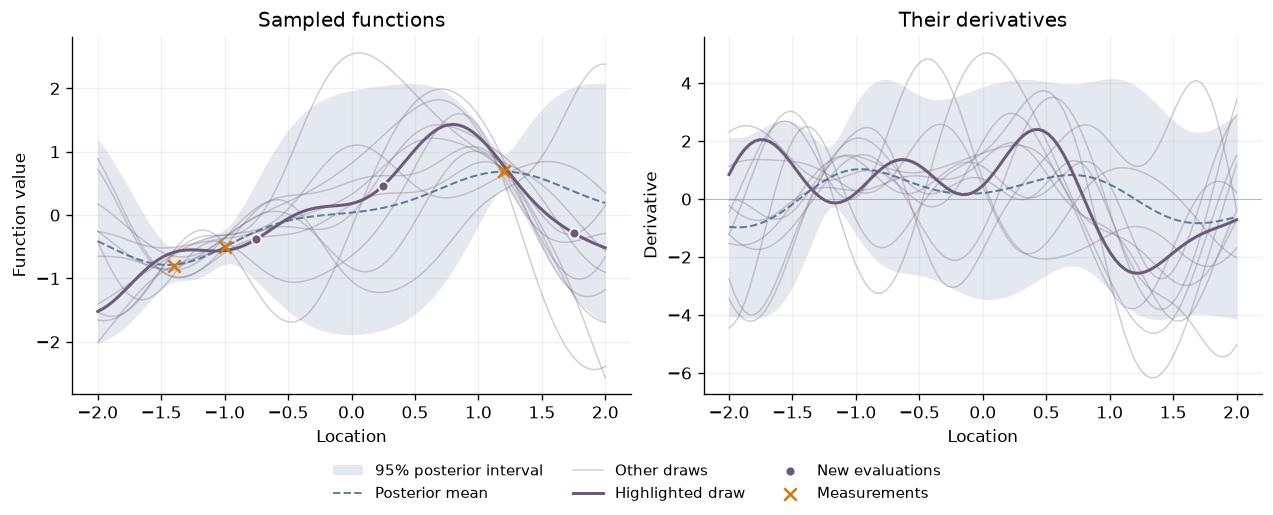

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
plot_posterior(axes[0], x_plot[:, 0], function_posterior, "function")
plot_draws(axes[0], x_plot[:, 0], other_values, function_values)
axes[0].scatter(
    new_locations[:, 0], new_values, color="#6D597A", edgecolors="white",
    s=35, zorder=4, label="New evaluations",
)
axes[0].scatter(
    x_observed[:, 0], y_observed,
    color="#D97706", marker="x", s=55, zorder=4, label="Measurements",
)
axes[0].set(title="Sampled functions", xlabel="Location", ylabel="Function value")

plot_posterior(axes[1], x_plot[:, 0], derivative_posterior, "derivative")
plot_draws(axes[1], x_plot[:, 0], other_derivatives, derivative_values)
axes[1].axhline(0.0, color="0.5", linewidth=0.6, alpha=0.5)
axes[1].set(title="Their derivatives", xlabel="Location", ylabel="Derivative")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center",
    ncol=3, frameon=False, fontsize=9,
)
plt.show()

The functions agree more closely near the measurements and vary more widely
in the large gap. The darker function and derivative belong to the same draw:
the derivative is positive where that function increases and negative where
it decreases.

Reuse `f_sample` when you need more evaluations or derivatives of this draw.
Construct it with a new random key when you want to sample another function.